# DS3006 Quantitative Finance: Group Assignment 2
Puneet Madan (U20230120) and Varun Arora (U20230011). Questions attempted: Q1, Q3 and Q5.

Put the NSE bhavcopy for 6 Nov 2026 in `data/` and run all cells from the top. Tables are saved to `tables/` and figures to `figs/`.

## Setup
Imports and the inputs from the brief. The option prices are the `ClsPric` values from the bhavcopy, at the same strikes as Table 1.

In [1]:
import os, sys, glob
import numpy as np, pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from math import log, sqrt, exp, pi, erf
from scipy.stats import norm
from scipy.optimize import brentq

# ============================ CONFIG ============================
BHAVCOPY   = "data/BhavCopy_NSE_FO_0_0_0_20261106_F_0000.csv"
SYMBOL, EXPIRY, TRADE_DATE = "NIFTY", "2026-11-23", "2026-11-06"
SPOT       = 25030.35                      # NIFTY 50 close, 6 Nov 2026
R          = 0.056                         # 5.60% p.a., continuously compounded (as in the assignment)
STRIKES    = [24500, 24750, 25000, 25250, 25500]   # same strikes as Table 1 of the assignment
ATM_STRIKE = 25000                         # Q3(a) and Q5 use the 25,000 strike
SIGMA_REF  = 0.1601                        # sigma quoted in Q4/Q5 of the assignment (reference data)
WIDE_LO, WIDE_HI, WIDE_MINVOL = 23500, 26500, 100   # wide smile: strike window, min contracts traded
# Reference dataset (Table 1 of the assignment), used only as a check on the code
REF = dict(K=[24500,24750,25000,25250,25500], C=[737.70,553.85,394.25,281.05,162.40],
           P=[143.50,209.00,298.75,416.95,565.65], F=25097.50)
# ================================================================
os.makedirs("figs", exist_ok=True); os.makedirs("tables", exist_ok=True)
plt.rcParams.update({"figure.dpi":130, "axes.grid":True, "grid.alpha":.25,
                     "axes.spines.top":False, "axes.spines.right":False})
T = (pd.Timestamp(EXPIRY)-pd.Timestamp(TRADE_DATE)).days/365      # 17/365

import io
from contextlib import redirect_stdout
from IPython.display import display, Image

def show(name, digits=4):
    """Display one of the saved result tables."""
    display(pd.read_csv(f"tables/{name}.csv").round(digits))

## Black-Scholes, implied volatility and Greeks
Our own pricing code, with a continuous yield q (q = 0 is the brief's plain Black-Scholes). SciPy is used only to cross-check.

In [2]:
# ------------- own Black-Scholes code (q = continuous carry/dividend yield, q=0 is plain BS) -------------
def Phi(x): return 0.5*(1+erf(x/sqrt(2)))
def phi(x): return exp(-0.5*x*x)/sqrt(2*pi)
def d1d2(S,K,T,r,q,s):
    d1=(log(S/K)+(r-q+0.5*s*s)*T)/(s*sqrt(T)); return d1, d1-s*sqrt(T)
def bs(S,K,T,r,q,s,cp):
    d1,d2=d1d2(S,K,T,r,q,s); eq,er=exp(-q*T),exp(-r*T)
    return S*eq*Phi(d1)-K*er*Phi(d2) if cp=="c" else K*er*Phi(-d2)-S*eq*Phi(-d1)
def vega(S,K,T,r,q,s):
    d1,_=d1d2(S,K,T,r,q,s); return S*exp(-q*T)*phi(d1)*sqrt(T)
def iv_newton(mkt,S,K,T,r,q,cp,s0=0.20,tol=1e-6,maxit=100):
    """Newton-Raphson for implied vol. Stops when |BS(sigma)-C_mkt| < tol. If the iteration leaves
    (0, 5], meets a vanishing vega or hits maxit, it falls back to Brent's method and says so."""
    s,rows=s0,[]
    for i in range(maxit):
        p,v=bs(S,K,T,r,q,s,cp),vega(S,K,T,r,q,s); err=p-mkt
        rows.append(dict(iteration=i,sigma=s,BS_price=p,error=err,vega=v))
        if abs(err)<tol: return s,pd.DataFrame(rows)
        if v<1e-8: break
        s=s-err/v
        if not 0<s<=5: break
    lo=max(S*exp(-q*T)-K*exp(-r*T),0) if cp=="c" else max(K*exp(-r*T)-S*exp(-q*T),0)
    if mkt<=lo: raise ValueError(f"price {mkt} at K={K} is below intrinsic value {lo:.2f}: no implied vol")
    s=brentq(lambda x:bs(S,K,T,r,q,x,cp)-mkt,1e-4,5,xtol=1e-12)
    print(f"  note: Newton did not converge for {cp.upper()} K={K}; Brent gives {s:.6f}")
    rows.append(dict(iteration=len(rows),sigma=s,BS_price=bs(S,K,T,r,q,s,cp),error=bs(S,K,T,r,q,s,cp)-mkt,vega=vega(S,K,T,r,q,s)))
    return s,pd.DataFrame(rows)
def greeks(S,K,T,r,q,s,cp):
    d1,d2=d1d2(S,K,T,r,q,s); eq,er=exp(-q*T),exp(-r*T)
    g=eq*phi(d1)/(S*s*sqrt(T)); v=S*eq*phi(d1)*sqrt(T); common=-S*eq*phi(d1)*s/(2*sqrt(T))
    if cp=="c":
        delta=eq*Phi(d1); th=common+q*S*eq*Phi(d1)-r*K*er*Phi(d2); rho=K*T*er*Phi(d2)
    else:
        delta=-eq*Phi(-d1); th=common-q*S*eq*Phi(-d1)+r*K*er*Phi(-d2); rho=-K*T*er*Phi(-d2)
    return {"Delta":delta,"Gamma":g,"Vega (per 1 vol pt)":v/100,
            "Theta (per calendar day)":th/365,"Rho (per 1% in r)":rho/100}

## Q1. Monte Carlo simulation of GBM
20,000 Euler paths with 252 steps and seed 2024, compared with the exact log-normal mean, variance and P(S₁ > 60).


=== Q1 ===
          Monte Carlo     Exact  Std. error (MC)  Abs. diff  Rel. diff (%)  Diff in std errors
E[S1]        54.34399  54.16435          0.11764    0.17964        0.33166             1.52699
Var(S1)     276.79378 276.28636          3.34006    0.50742        0.18366             0.15192
P(S1>60)      0.31640   0.31169          0.00329    0.00471        1.51183             1.43291


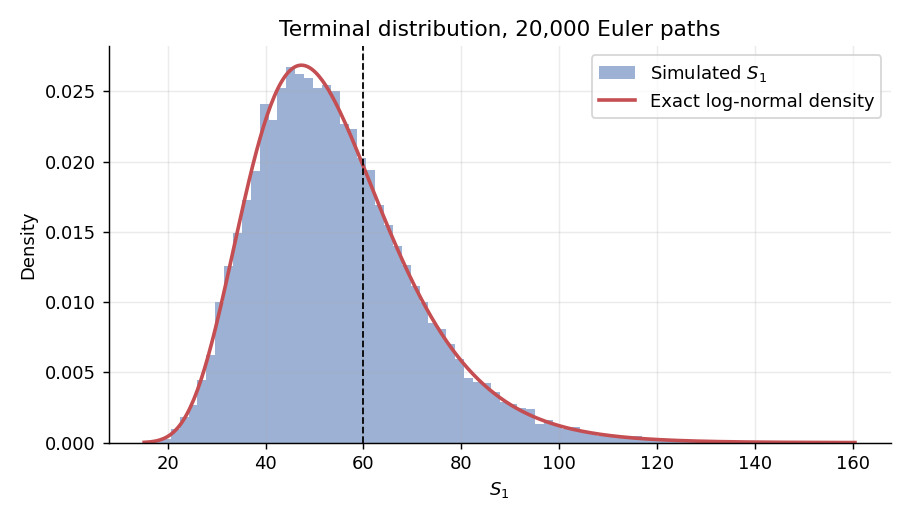

In [3]:
# ================================ Q1 ================================
def q1():
    S0,mu,sg=50.0,0.08,0.30; n,M,T1=252,20_000,1.0; dt=T1/n
    rng=np.random.default_rng(2024)
    Z=rng.standard_normal((M,n)); S=np.full(M,S0)
    for i in range(n): S=S+mu*S*dt+sg*S*np.sqrt(dt)*Z[:,i]
    mc_mean,mc_var=S.mean(),S.var(ddof=1); se_mean=S.std(ddof=1)/np.sqrt(M)
    ex_mean=S0*np.exp(mu*T1); ex_var=S0**2*np.exp(2*mu*T1)*(np.exp(sg**2*T1)-1)
    mc_p=(S>60).mean(); se_p=np.sqrt(mc_p*(1-mc_p)/M)
    ex_p=1-norm.cdf((np.log(60/S0)-(mu-0.5*sg**2)*T1)/(sg*np.sqrt(T1)))
    # standard error of the variance estimate: bootstrap (the normal-theory formula is poor for a log-normal)
    B=300; bv=np.random.default_rng(1).choice(S,size=(B,M)).var(axis=1,ddof=1); se_var=bv.std()
    # mean of the Euler scheme itself: E[S_n] = S0 (1 + mu dt)^n, so its bias is exact and known
    euler_mean=S0*(1+mu*dt)**n
    pd.DataFrame([dict(euler_mean=euler_mean,euler_bias=euler_mean-S0*np.exp(mu*T1),bootstrap_B=B,bootstrap_seed=1,
                       M=M,n=n,seed=2024)]).to_csv("tables/q1_extra.csv",index=False)
    df=pd.DataFrame({"Monte Carlo":[mc_mean,mc_var,mc_p],"Exact":[ex_mean,ex_var,ex_p],
                     "Std. error (MC)":[se_mean,se_var,se_p]},index=["E[S1]","Var(S1)","P(S1>60)"])
    df["Abs. diff"]=(df["Monte Carlo"]-df["Exact"]).abs()
    df["Rel. diff (%)"]=100*df["Abs. diff"]/df["Exact"]
    df["Diff in std errors"]=(df["Monte Carlo"]-df["Exact"])/df["Std. error (MC)"]
    df.to_csv("tables/q1_results.csv")
    fig,ax=plt.subplots(figsize=(7,4))
    ax.hist(S,bins=80,density=True,alpha=.55,color="#4C72B0",label="Simulated $S_1$")
    x=np.linspace(S.min(),S.max(),400); m_,s_=np.log(S0)+(mu-0.5*sg**2)*T1,sg*np.sqrt(T1)
    ax.plot(x,norm.pdf(np.log(x),m_,s_)/x,color="#C44E52",lw=2,label="Exact log-normal density")
    ax.axvline(60,color="k",ls="--",lw=1); ax.set_xlabel("$S_1$"); ax.set_ylabel("Density")
    ax.set_title("Terminal distribution, 20,000 Euler paths"); ax.legend()
    fig.tight_layout(); fig.savefig("figs/q1_hist.png"); plt.close(fig)
    print("\n=== Q1 ==="); print(df.to_string(float_format=lambda v:f"{v:.5f}"))

q1()
Image("figs/q1_hist.png")

## Q3 and Q5: option data and calculations
Loads the bhavcopy closes and runs every Q3 and Q5 calculation. The results are shown part by part below.

In [4]:
# ============================ NSE data ============================
def load_chain():
    path=BHAVCOPY if os.path.exists(BHAVCOPY) else (glob.glob("data/BhavCopy_NSE_FO*") or [None])[0]
    if path is None: sys.exit("Bhavcopy not found in ./data/ - download it from nseindia.com (see README).")
    raw=pd.read_csv(path,usecols=lambda c:c.strip() in
        {"TckrSymb","XpryDt","FinInstrmTp","StrkPric","OptnTp","ClsPric","UndrlygPric","TtlTradgVol"})
    raw.columns=[c.strip() for c in raw.columns]
    raw["XpryDt"]=pd.to_datetime(raw["XpryDt"]).dt.strftime("%Y-%m-%d")
    n=raw[(raw.TckrSymb.str.strip()==SYMBOL)&(raw.XpryDt==EXPIRY)]
    o=n[n.FinInstrmTp=="IDO"]
    if o.empty: sys.exit(f"No {SYMBOL} options for expiry {EXPIRY}.")
    F=float(n[n.FinInstrmTp=="IDF"].ClsPric.iloc[0])
    return (o[o.OptnTp=="CE"].set_index("StrkPric"), o[o.OptnTp=="PE"].set_index("StrkPric"),
            F, float(o.UndrlygPric.iloc[0]))

def parity_forward(ce,pe,r=R):
    """Forward implied by put-call parity, F = K + (C - P) e^{rT}, averaged over strikes within 300 points
    of spot where both the call and the put traded at least 1,000 contracts."""
    liq=[k for k in ce.index if k in pe.index and abs(k-SPOT)<=300 and min(ce.TtlTradgVol[k],pe.TtlTradgVol[k])>=1000]
    Fk=[k+(ce.ClsPric[k]-pe.ClsPric[k])*exp(r*T) for k in liq]
    pd.DataFrame({"Strike":liq,"Call":[ce.ClsPric[k] for k in liq],"Put":[pe.ClsPric[k] for k in liq],
                  "Implied forward":Fk}).to_csv("tables/parity_forward.csv",index=False)
    return float(np.mean(Fk)), len(liq)

def implied_q(Fwd): return R-log(Fwd/SPOT)/T

# ====================== Q3 / Q5 for one choice of carry yield q ======================
def fd_checks(tag,q,sig,atm):
    """Analytic Greeks against central finite differences, for the call and the put, saved as a table."""
    fd=lambda f,x,e:(f(x+e)-f(x-e))/(2*e); rows=[]
    for cp in ("c","p"):
        g=greeks(SPOT,atm,T,R,q,sig,cp); V=lambda S=SPOT,t=T,r=R,s=sig:bs(S,atm,t,r,q,s,cp)
        num={"Delta":fd(lambda x:V(S=x),SPOT,1.0),
             "Gamma":(V(S=SPOT+1)-2*V()+V(S=SPOT-1)),
             "Vega (per 1 vol pt)":fd(lambda x:V(s=x),sig,1e-5)/100,
             "Theta (per calendar day)":-fd(lambda x:V(t=x),T,1e-6)/365,
             "Rho (per 1% in r)":fd(lambda x:V(r=x),R,1e-5)/100}
        for k,v in num.items():
            rows.append(dict(option="Call" if cp=="c" else "Put",greek=k,analytic=g[k],finite_diff=v,rel_error=abs(g[k]-v)/abs(g[k])))
    df=pd.DataFrame(rows); df.to_csv(f"tables/fd_checks_{tag}.csv",index=False); return df

def analyse(tag,q,K,C,P,atm):
    """Newton trace for the ATM call, IVs for all strikes, parity residual, Q5 price and Greeks."""
    i=list(K).index(atm)
    sig,trace=iv_newton(C[i],SPOT,atm,T,R,q,"c"); trace.to_csv(f"tables/q3a_newton_trace_{tag}.csv",index=False)
    rows=[]
    for k,c,p in zip(K,C,P):
        ivc,_=iv_newton(c,SPOT,k,T,R,q,"c"); ivp,_=iv_newton(p,SPOT,k,T,R,q,"p")
        rows.append(dict(Strike=k,Call_IV_pct=100*ivc,Put_IV_pct=100*ivp))
    iv=pd.DataFrame(rows); iv["Call-Put gap (vol pts)"]=iv.Call_IV_pct-iv.Put_IV_pct
    iv["C-P"]=C-P; iv["S0e^-qT-Ke^-rT"]=SPOT*np.exp(-q*T)-K*np.exp(-R*T); iv["Parity residual"]=iv["C-P"]-iv["S0e^-qT-Ke^-rT"]
    iv.to_csv(f"tables/q3b_iv_table_{tag}.csv",index=False)
    chk=max(abs(brentq(lambda s:bs(SPOT,k,T,R,q,s,"c")-c,1e-4,3)-v/100) for k,c,v in zip(K,C,iv.Call_IV_pct))
    d1,d2=d1d2(SPOT,atm,T,R,q,sig); call,put=bs(SPOT,atm,T,R,q,sig,"c"),bs(SPOT,atm,T,R,q,sig,"p")
    q5a=pd.DataFrame({"value":[q,sig,d1,d2,Phi(d1),Phi(d2),call,put]},
        index=["q used","sigma used","d1","d2","N(d1)","N(d2)","Call price","Put price"]); q5a.to_csv(f"tables/q5a_prices_{tag}.csv")
    gc,gp=greeks(SPOT,atm,T,R,q,sig,"c"),greeks(SPOT,atm,T,R,q,sig,"p")
    pd.DataFrame({"Call":gc,"Put":gp}).to_csv(f"tables/q5b_greeks_{tag}.csv")
    checks=fd_checks(tag,q,sig,atm)
    print(f"\n--- {tag}: q={q:.4%}, ATM ({atm}) call IV = {sig:.4%}, Newton iterations = {len(trace)-1}, max|Newton-Brent| = {chk:.1e}")
    print(trace.to_string(index=False)); print(iv.round(4).to_string(index=False))
    print(q5a.to_string(float_format=lambda v:f"{v:.6f}")); print(pd.DataFrame({"Call":gc,"Put":gp}).to_string(float_format=lambda v:f"{v:.6f}"))
    print(f"FD checks: max relative error {checks.rel_error.max():.1e}",
          "| Delta_C-Delta_P =",round(gc["Delta"]-gp["Delta"],6),"vs exp(-qT) =",round(exp(-q*T),6))
    return dict(tag=tag,q=q,sig=sig,iv=iv,gc=gc,gp=gp)

def q3_q5():
    ce,pe,F,U=load_chain()
    K=np.array(STRIKES,float); C=ce.ClsPric[K].values; P=pe.ClsPric[K].values
    pd.DataFrame({"Strike":K,"Call":C,"Put":P}).to_csv("tables/market_data.csv",index=False)
    Fpar,nliq=parity_forward(ce,pe)
    print(f"\n=== Market data (bhavcopy {TRADE_DATE}) ===\nSpot {SPOT}, UndrlygPric in file {U}, futures close {F}, T={T:.6f}, r={R:.4%}")
    print(pd.DataFrame({"Strike":K,"Call":C,"Put":P}).to_string(index=False))
    fwds={"baseline":("Spot, q = 0 (assignment)",SPOT*exp(R*T)),"futures":("Futures close",F),"parity":("Put-call parity",Fpar)}
    res={t:analyse(t,implied_q(f) if t!="baseline" else 0.0,K,C,P,ATM_STRIKE) for t,(n_,f) in fwds.items()}
    rows=[]
    for t,(nm,f) in fwds.items():
        r_=res[t]; i=list(K).index(ATM_STRIKE)
        rows.append({"Forward":nm,"F":f,"q (%)":100*r_["q"],"ATM call IV (%)":r_["iv"].Call_IV_pct[i],"ATM put IV (%)":r_["iv"].Put_IV_pct[i],
                     "Mean |call-put| IV gap (vol pts)":r_["iv"]["Call-Put gap (vol pts)"].abs().mean(),
                     "Mean parity residual":r_["iv"]["Parity residual"].mean()})
    cmp_=pd.DataFrame(rows); cmp_.to_csv("tables/q3_forward_comparison.csv",index=False)
    print("\n=== Forward comparison ==="); print(cmp_.round(4).to_string(index=False))
    # figure: five-strike IVs, baseline vs carry-adjusted
    b,a=res["baseline"]["iv"],res["futures"]["iv"]
    fig,ax=plt.subplots(figsize=(7,4))
    ax.plot(K,b.Call_IV_pct,"o:",color="#9DB4D8",label="Call IV, q = 0"); ax.plot(K,b.Put_IV_pct,"s:",color="#E3A3A6",label="Put IV, q = 0")
    ax.plot(K,a.Call_IV_pct,"o-",color="#4C72B0",label="Call IV, futures forward"); ax.plot(K,a.Put_IV_pct,"s--",color="#C44E52",label="Put IV, futures forward")
    ax.axvline(SPOT,color="grey",ls=":",lw=1); ax.set_xlabel("Strike"); ax.set_ylabel("Implied volatility (%)")
    ax.set_title(f"{SYMBOL} implied volatility at the five Q3 strikes, {TRADE_DATE}",fontsize=10); ax.legend(fontsize=8)
    fig.tight_layout(); fig.savefig("figs/q3_smile.png"); plt.close(fig)
    q5_brief()
    # Greeks figure for Q5 as stated in the brief (sigma = 16.01%, q = 0)
    q=0.0; sig=SIGMA_REF; Ss=np.linspace(SPOT*0.96,SPOT*1.05,200)
    fig,axs=plt.subplots(1,3,figsize=(11,3.4))
    axs[0].plot(Ss,[greeks(s,ATM_STRIKE,T,R,q,sig,"c")["Delta"] for s in Ss],label="Call"); axs[0].plot(Ss,[greeks(s,ATM_STRIKE,T,R,q,sig,"p")["Delta"] for s in Ss],label="Put"); axs[0].set_title("Delta"); axs[0].legend()
    axs[1].plot(Ss,[greeks(s,ATM_STRIKE,T,R,q,sig,"c")["Gamma"] for s in Ss],color="#55A868"); axs[1].set_title("Gamma (call = put)")
    axs[2].plot(Ss,[greeks(s,ATM_STRIKE,T,R,q,sig,"c")["Vega (per 1 vol pt)"] for s in Ss],color="#8172B2"); axs[2].set_title("Vega per vol point")
    axs[0].set_ylabel("Delta"); axs[1].set_ylabel("Gamma (per index point)"); axs[2].set_ylabel("Vega (Rs per vol point)")
    for a_ in axs: a_.axvline(SPOT,color="grey",ls=":",lw=1); a_.set_xlabel("NIFTY level")
    fig.tight_layout(); fig.savefig("figs/q5_greeks.png"); plt.close(fig)
    return ce,pe,F,Fpar

# ===================== Q5 exactly as stated: sigma = 16.01%, q = 0 =====================
def q5_brief():
    q,sig=0.0,SIGMA_REF; d1,d2=d1d2(SPOT,ATM_STRIKE,T,R,q,sig)
    c,p=bs(SPOT,ATM_STRIKE,T,R,q,sig,"c"),bs(SPOT,ATM_STRIKE,T,R,q,sig,"p")
    pd.DataFrame({"value":[sig,d1,d2,Phi(d1),Phi(d2),c,p]},index=["sigma used","d1","d2","N(d1)","N(d2)","Call price","Put price"]).to_csv("tables/q5a_brief.csv")
    g=pd.DataFrame({"Call":greeks(SPOT,ATM_STRIKE,T,R,q,sig,"c"),"Put":greeks(SPOT,ATM_STRIKE,T,R,q,sig,"p")}); g.to_csv("tables/q5b_brief.csv")
    chk=fd_checks("brief",q,sig,ATM_STRIKE)
    print(f"\n=== Q5 (sigma = {sig:.2%}, q = 0, K = {ATM_STRIKE}) ===\nd1={d1:.6f} d2={d2:.6f} N(d1)={Phi(d1):.6f} N(d2)={Phi(d2):.6f} call={c:.4f} put={p:.4f}")
    print(g.to_string(float_format=lambda v:f"{v:.6f}")); print(f"FD checks: max relative error {chk.rel_error.max():.1e}")

# ============================ wide-range smile ============================
def q3_wide(ce,pe,F,Fpar):
    out={}; print("\n=== Q3(b) wide smile (out-of-the-money option at each strike) ===")
    for name,Fw in (("futures",F),("parity",Fpar)):
        q=implied_q(Fw); rows=[]; n_window=n_dropped=0
        for k in sorted(set(ce.index)&set(pe.index)):
            if not WIDE_LO<=k<=WIDE_HI: continue
            n_window+=1
            cp,row=("p",pe.loc[k]) if k<Fw else ("c",ce.loc[k])
            if row.TtlTradgVol<WIDE_MINVOL or row.ClsPric<=0.5: n_dropped+=1; continue
            s,_=iv_newton(row.ClsPric,SPOT,k,T,R,q,cp)
            rows.append(dict(Strike=k,Type="PE" if cp=="p" else "CE",Price=row.ClsPric,Volume=row.TtlTradgVol,
                             LogMoneyness=log(k/Fw),IV_pct=100*s))
        df=pd.DataFrame(rows); df=df[(df.IV_pct>1)&(df.IV_pct<100)]; df.to_csv(f"tables/q3_wide_smile_{name}.csv",index=False); out[name]=df
        c=np.polyfit(df.LogMoneyness,df.IV_pct,2)
        step=df[df.Strike>=Fw].IV_pct.iloc[0]-df[df.Strike<Fw].IV_pct.iloc[-1]
        print(f"[{name}] forward {Fw:,.2f}, q={q:.3%}, {len(df)} strikes: IV = {c[2]:.2f} {c[1]:+.1f}k {c[0]:+.0f}k^2 (k=ln K/F), "
              f"min at K={Fw*exp(-c[1]/(2*c[0])):,.0f}, put/call step = {step:+.2f} vol pts")
        imin=df.IV_pct.idxmin()
        pd.DataFrame([dict(forward=name,F=Fw,q_pct=100*q,n_window=n_window,n_dropped=n_dropped,n_strikes=len(df),
                           data_min_iv=df.IV_pct[imin],data_min_strike=df.Strike[imin],a=c[2],b=c[1],c=c[0],
                           min_strike=Fw*exp(-c[1]/(2*c[0])),step=step)]).to_csv(f"tables/q3_wide_fit_{name}.csv",index=False)
    sel=[23500,24000,24500,25000,25250,25500,26000,26500]
    t=out["futures"][out["futures"].Strike.isin(sel)][["Strike","Type","Price","Volume","IV_pct"]].merge(
        out["parity"][["Strike","IV_pct"]],on="Strike",suffixes=("_futures","_parity"))
    t.to_csv("tables/q3_wide_selected.csv",index=False); print(t.round(3).to_string(index=False))
    fig,ax=plt.subplots(figsize=(7.5,4.2))
    for name,col,mk in (("futures","#4C72B0","o"),("parity","#C44E52","s")):
        ax.plot(out[name].Strike,out[name].IV_pct,mk+"-",ms=3.5,lw=1.2,color=col,label=f"OTM IV, forward = {name}")
    ax.axvline(SPOT,color="grey",ls=":",lw=1); ax.set_xlabel("Strike"); ax.set_ylabel("Implied volatility (%)")
    ax.set_title(f"{SYMBOL} {EXPIRY} smile on {TRADE_DATE} (OTM options, volume >= {WIDE_MINVOL})",fontsize=10)
    ax.legend(); fig.tight_layout(); fig.savefig("figs/q3_smile_wide.png",dpi=150); plt.close(fig)

# ===================== check on the assignment's reference data =====================
def reference_check():
    K,C,P=np.array(REF["K"],float),np.array(REF["C"]),np.array(REF["P"])
    print("\n=== Check on the assignment's reference dataset (Table 1, q = 0) ===")
    r_=analyse("reference",0.0,K,C,P,ATM_STRIKE)
    Fref=REF["F"]; print(f"Reference futures {Fref} vs S0*exp(rT) = {SPOT*exp(R*T):.2f}; implied q = {implied_q(Fref):.3%}")
    pd.DataFrame([dict(F_mkt=Fref,S0_exp_rT=SPOT*exp(R*T),implied_q_pct=100*implied_q(Fref))]).to_csv("tables/ref_forward_check.csv",index=False)

with redirect_stdout(io.StringIO()):
    ce, pe, F, Fpar = q3_q5()
    q3_wide(ce, pe, F, Fpar)
    reference_check()
show("market_data", 2)

,Strike,Call,Put
0,24500.0,673.75,156.30
1,24750.0,491.45,229.30
2,25000.0,344.30,325.10
3,25250.0,227.50,456.60
4,25500.0,142.55,622.65


### Q3(a) Newton-Raphson for the 25,000 call
σₙ₊₁ = σₙ − (BS(σₙ) − C_mkt) / vega, starting at σ₀ = 20% and stopping once |BS(σ) − C_mkt| < 10⁻⁶. First on the bhavcopy close, then on the brief's Table 1 price as a check.

In [5]:
show("q3a_newton_trace_baseline", 8)
show("q3a_newton_trace_reference", 8)

,iteration,sigma,BS_price,error,vega
0,0,0.200000,479.572146,135.272146,2142.011945
1,1,0.136848,344.535459,0.235459,2132.760899
2,2,0.136738,344.300002,0.000002,2132.732432
3,3,0.136738,344.300000,-0.000000,2132.732432


,iteration,sigma,BS_price,error,vega
0,0,0.200000,479.572146,8.532215e+01,2142.011945
1,1,0.160167,394.329419,7.941880e-02,2137.500605
2,2,0.160130,394.250000,1.100000e-07,2137.494691


### Q3(b) Implied volatilities and the smile
Call and put IVs at all five strikes with q = 0, for the bhavcopy closes and for Table 1.

,Strike,Call_IV_pct,Put_IV_pct,Call-Put gap (vol pts),C-P,S0e^-qT-Ke^-rT,Parity residual
0,24500.0,13.2785,17.9472,-4.6686,517.45,594.1681,-76.7181
1,24750.0,13.3944,17.6109,-4.2165,262.15,344.8193,-82.6693
2,25000.0,13.6738,17.2439,-3.5701,19.20,95.4705,-76.2705
3,25250.0,13.7928,17.3323,-3.5395,-229.10,-153.8783,-75.2217
4,25500.0,13.9187,17.8699,-3.9512,-480.10,-403.2271,-76.8729


,Strike,Call_IV_pct,Put_IV_pct,Call-Put gap (vol pts),C-P,S0e^-qT-Ke^-rT,Parity residual
0,24500.0,17.2143,17.2124,0.0018,594.20,594.1681,0.0319
1,24750.0,16.5943,16.5927,0.0015,344.85,344.8193,0.0307
2,25000.0,16.0130,16.0116,0.0014,95.50,95.4705,0.0295
3,25250.0,16.3152,15.4700,0.8452,-135.90,-153.8783,17.9783
4,25500.0,14.9612,14.9624,-0.0012,-403.25,-403.2271,-0.0229


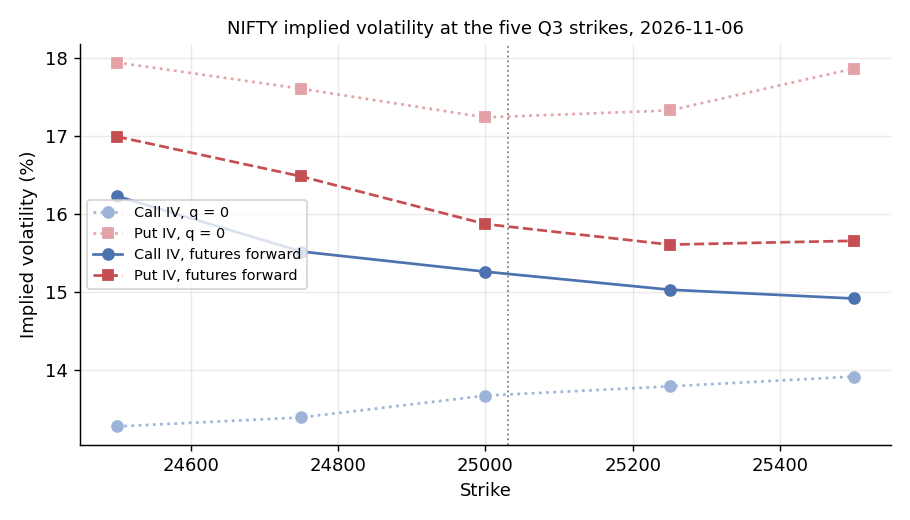

In [6]:
show("q3b_iv_table_baseline")
show("q3b_iv_table_reference")
Image("figs/q3_smile.png")

### Q3 extension: correcting the forward and the full smile
With q = 0 the call and put IVs disagree, so the forward is taken from the futures or from put-call parity. The full smile uses the out-of-the-money option at every strike from 23,500 to 26,500.

,Forward,F,q (%),ATM call IV (%),ATM put IV (%),Mean |call-put| IV gap (vol pts),Mean parity residual
0,"Spot, q = 0 (assignment)",25095.7199,0.0000,13.6738,17.2439,3.9892,-77.5505
1,Futures close,25032.4000,5.4242,15.2640,15.8751,0.7314,-14.3956
2,Put-call parity,25017.7473,6.6813,15.6172,15.5473,0.1081,0.2190


,Strike,Type,Price,Volume,IV_pct_futures,IV_pct_parity
0,23500.0,PE,47.20,78679,21.791,21.642
1,24000.0,PE,78.85,184751,18.965,18.792
2,24500.0,PE,156.30,256733,16.997,16.773
3,25000.0,PE,325.10,74127,15.875,15.547
4,25250.0,CE,227.50,9576,15.033,15.313
5,25500.0,CE,142.55,256329,14.920,15.148
6,26000.0,CE,56.75,180608,15.685,15.853
7,26500.0,CE,25.25,98509,17.119,17.258


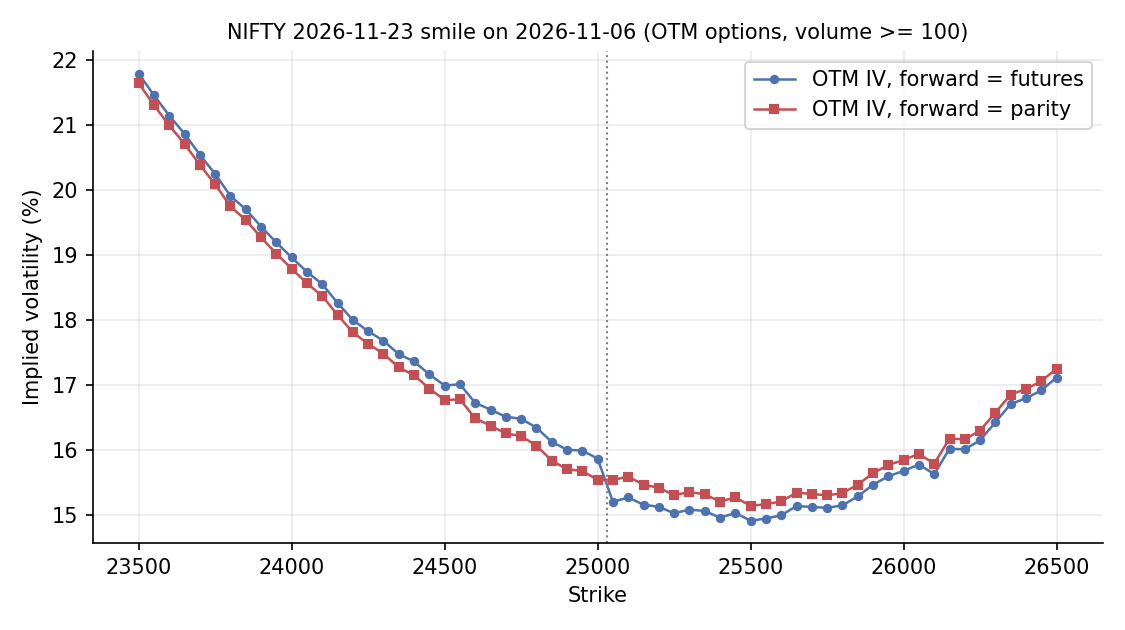

In [7]:
show("q3_forward_comparison")
show("q3_wide_selected", 3)
Image("figs/q3_smile_wide.png")

## Q5(a) Black-Scholes prices
The 25,000 call and put with σ = 16.01% and q = 0, with d₁, d₂, N(d₁) and N(d₂).

In [8]:
show("q5a_brief", 6)

,Unnamed: 0,value
0,sigma used,0.160100
1,d1,0.127878
2,d2,0.093326
3,N(d1),0.550877
4,N(d2),0.537178
5,Call price,394.185592
6,Put price,298.715074


## Q5(b) Greeks
Delta, Gamma, Vega per vol point, Theta per calendar day and Rho per 1% change in r, checked against finite differences.

,Unnamed: 0,Call,Put
0,Delta,0.550877,-0.449123
1,Gamma,0.000458,0.000458
2,Vega (per 1 vol pt),21.374899,21.374899
3,Theta (per calendar day),-12.120103,-8.294478
4,Rho (per 1% in r),6.238517,-5.374989


,option,greek,analytic,finite_diff,rel_error
0,Call,Delta,0.550877,0.550877,3.000000e-08
1,Call,Gamma,0.000458,0.000458,1.000000e-07
2,Call,Vega (per 1 vol pt),21.374899,21.374899,0.000000e+00
3,Call,Theta (per calendar day),-12.120103,-12.120103,0.000000e+00
4,Call,Rho (per 1% in r),6.238517,6.238517,0.000000e+00
5,Put,Delta,-0.449123,-0.449123,3.000000e-08
6,Put,Gamma,0.000458,0.000458,1.100000e-07
7,Put,Vega (per 1 vol pt),21.374899,21.374899,0.000000e+00
8,Put,Theta (per calendar day),-8.294478,-8.294478,0.000000e+00
9,Put,Rho (per 1% in r),-5.374989,-5.374989,0.000000e+00


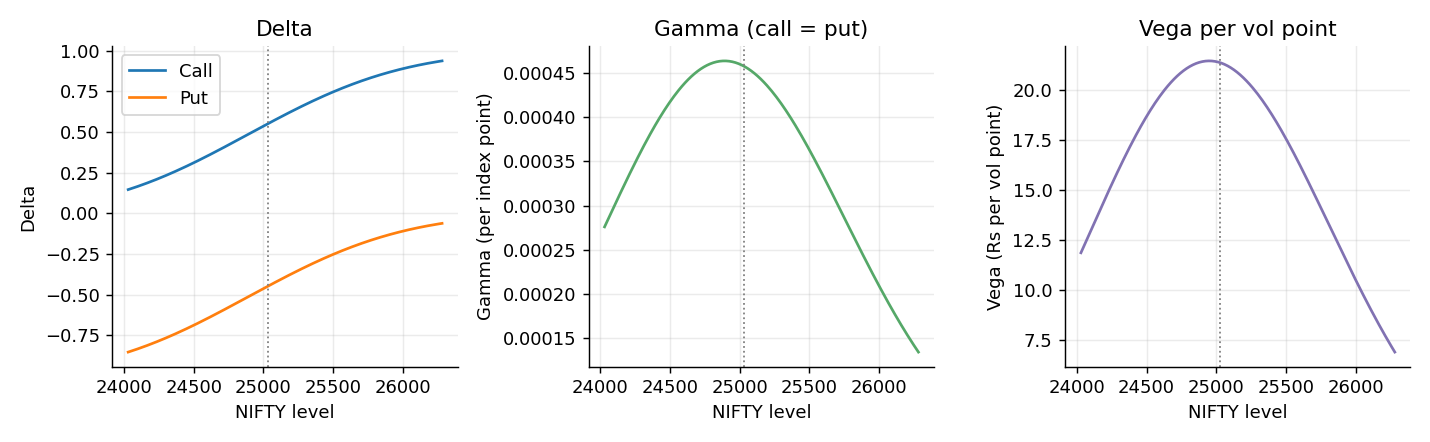

In [9]:
show("q5b_brief", 6)
show("fd_checks_brief", 8)
Image("figs/q5_greeks.png")